# Black-Scholes under volatility uncertainty
### Input sensitivity, model mismatch, and Monte Carlo validation

A pricing implementation can be numerically consistent with its assumptions while still failing to reproduce prices from a different market model. This study separates three sources of uncertainty: the volatility input, the specification of the pricing model, and the simulation evidence used to assess that model.

The analysis proceeds in three stages. First, a controlled sensitivity experiment measures how volatility-input errors affect European call prices. Second, an equal-probability mixture of two volatility regimes provides a benchmark against which a single-volatility Black-Scholes model is calibrated and evaluated. Third, repeated Monte Carlo trials measure how reliably a specified validation procedure detects the resulting pricing discrepancies.

The companion notebook, `pricing_validation.ipynb`, verifies analytical prices against risk-neutral Monte Carlo estimates and establishes the two-regime simulation benchmark. This notebook builds on that verification to distinguish **the existence of a pricing error** from **the ability of a simulation-based test to detect it**. All prices and calibration inputs in this study are synthetic; the results do not establish accuracy in real options markets.

### Model setting

| Quantity | Specification |
|---|---|
| Initial stock price, $S_0$ | 100 dollars |
| Time to expiration, $T$ | 1 year |
| Continuously compounded risk-free rate, $r$ | 4% |
| Baseline volatility | 20% annually |
| Sensitivity strikes | 90, 100, and 110 dollars |
| Alternative benchmark | Equal risk-neutral weights on 10% and 30% volatility |

Option prices and pricing errors are reported in **dollars per share**. Volatilities are annualized and represented as decimals in the calculations.

In [1]:
from pathlib import Path
import platform
import json

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm, binomtest
from IPython.display import display, Markdown

try:
    from bs_model import bs_call
except ModuleNotFoundError as exc:
    if exc.name == "bs_model":
        raise ModuleNotFoundError(
            "The project dependency bs_model.py is not available on the Python import path. "
            "The common bs_call pricing function is required."
        ) from exc
    raise

# Financial assumptions held fixed across the experiments.
S0, maturity, rate = 100.0, 1.0, 0.04
sigma_benchmark = 0.20
strikes = [90, 100, 110]
sigmas = [0.10, 0.15, 0.20, 0.25, 0.30]

# Fixed settings for the repeated-trial validation experiment.
test_strikes = np.array([80.0, 90.0, 110.0, 120.0])
test_sets = {
    "near": np.array([1, 2]),  # K = 90, 110
    "wide": np.array([0, 3]),  # K = 80, 120
}
worlds = {
    "control": [(1.0, 0.20)],
    "mixture": [(0.5, 0.10), (0.5, 0.30)],
}
calibration_strike = 100.0
budgets = [1_000, 10_000, 100_000]
tolerances = np.array([0.0, 0.05, 0.10])
primary_tolerance = 0.10
alpha = 0.05
detection_target = 0.90
REPETITIONS = 500
SEED = 20261103

# Two contracts are tested within each near/wide procedure.
assert all(len(indices) == 2 for indices in test_sets.values())
critical = norm.ppf(1 - alpha / (2 * 2))

results_dir = Path("results") / "volatility_validation"
figures_dir = Path("figures") / "volatility_validation"
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
saved_figures = []


def save_figure(fig, name):
    """Export one figure, display it in the notebook, and close it."""
    fig.tight_layout()
    destination = figures_dir / name
    fig.savefig(destination, dpi=200, bbox_inches="tight")
    saved_figures.append(str(destination))
    plt.show()
    plt.close(fig)


versions = {
    "python": platform.python_version(),
    "numpy": np.__version__, "scipy": scipy.__version__,
    "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
}
print("Environment:", versions)

# A regression check for the shared function; not a proof for all inputs.
assert np.isclose(
    bs_call(S0, 100, maturity, rate, sigma_benchmark),
    9.925053717274437, atol=1e-10, rtol=0,
)
print("Shared bs_call baseline check passed.")

Environment: {'python': '3.11.9', 'numpy': '2.4.6', 'scipy': '1.17.1', 'pandas': '3.1.0', 'matplotlib': '3.11.2'}
Shared bs_call baseline check passed.


## 1. Sensitivity to volatility inputs

The first experiment isolates the effect of a misspecified volatility input while leaving the pricing model and other parameters unchanged. Each of three strikes is priced at five volatility levels: 10%, 15%, 20%, 25%, and 30%. The resulting 15 scenarios are compared with Black-Scholes prices calculated at the 20% baseline.

For each strike, signed dollar and relative pricing errors are defined as

$$
E_{\mathrm{dollar}}(\sigma)
=C_{\mathrm{BS}}(\sigma)-C_{\mathrm{BS}}(0.20),
\qquad
E_{\mathrm{relative}}(\sigma)
=100\frac{C_{\mathrm{BS}}(\sigma)-C_{\mathrm{BS}}(0.20)}
{C_{\mathrm{BS}}(0.20)}.
$$

The benchmark in this section is a specified Black-Scholes price, not an observed market quote. These comparisons quantify input sensitivity rather than empirical accuracy or changes in volatility during an option's life.

In [2]:
benchmark_prices = {
    strike: bs_call(S0, strike, maturity, rate, sigma_benchmark)
    for strike in strikes
}
scenario_prices = {
    (strike, sigma): bs_call(S0, strike, maturity, rate, sigma)
    for strike in strikes
    for sigma in sigmas
}

sensitivity_rows = []
for (strike, sigma), price in scenario_prices.items():
    benchmark = benchmark_prices[strike]
    signed_error = price - benchmark
    sensitivity_rows.append({
        "Strike": strike,
        "Volatility": sigma,
        "Model Price": price,
        "Benchmark Price": benchmark,
        "Dollar Error": signed_error,
        "Relative Error (%)": 100 * signed_error / benchmark,
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
assert np.isfinite(sensitivity_df.to_numpy(dtype=float)).all()
assert (sensitivity_df["Model Price"] >= 0).all()
assert np.allclose(
    sensitivity_df.loc[
        np.isclose(sensitivity_df["Volatility"], sigma_benchmark), "Dollar Error"
    ], 0.0,
)
for strike in strikes:
    prices = [scenario_prices[(strike, sigma)] for sigma in sigmas]
    assert np.all(np.diff(prices) > 0)

display(sensitivity_df.round(5))

,Strike,Volatility,Model Price,Benchmark Price,Dollar Error,Relative Error (%)
0,90,0.10,13.83135,16.06043,-2.22908,-13.87931
1,90,0.15,14.75898,16.06043,-1.30145,-8.10346
2,90,0.20,16.06043,16.06043,0.00000,0.00000
3,90,0.25,17.55303,16.06043,1.49260,9.29363
4,90,0.30,19.14914,16.06043,3.08871,19.23181
5,100,0.10,6.17846,9.92505,-3.74659,-37.74884
6,100,0.15,8.02860,9.92505,-1.89645,-19.10775
7,100,0.20,9.92505,9.92505,0.00000,0.00000
8,100,0.25,11.83705,9.92505,1.91199,19.26431
9,100,0.30,13.75326,9.92505,3.82821,38.57119


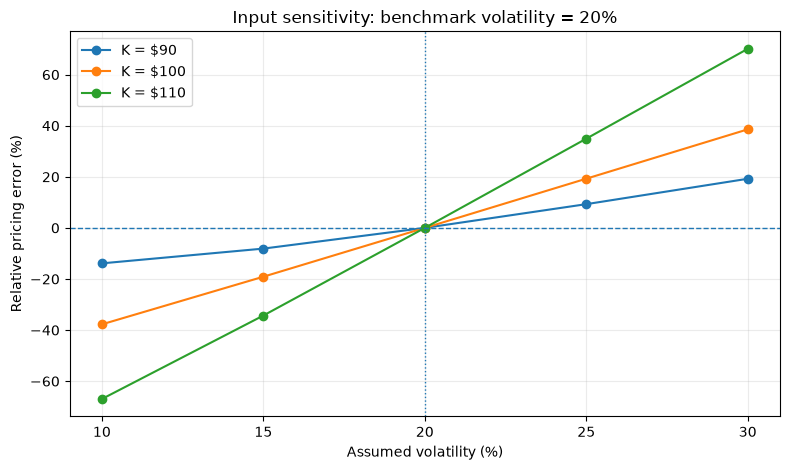

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for strike in strikes:
    subset = sensitivity_df[sensitivity_df["Strike"] == strike]
    ax.plot(subset["Volatility"] * 100, subset["Relative Error (%)"],
            marker="o", label=f"K = ${strike}")
ax.axhline(0, linestyle="--", linewidth=1)
ax.axvline(100 * sigma_benchmark, linestyle=":", linewidth=1)
ax.set(xlabel="Assumed volatility (%)", ylabel="Relative pricing error (%)",
       title="Input sensitivity: benchmark volatility = 20%")
ax.set_xticks(np.array(sigmas) * 100)
ax.legend()
ax.grid(alpha=0.25)
save_figure(fig, "01_volatility_sensitivity.png")

### Sensitivity results

Call prices increase with assumed volatility for each tested strike. The 110-strike option has the largest percentage deviations: using 10% rather than 20% volatility reduces its price by approximately 66.97%, while using 30% increases it by approximately 70.10%. Percentage errors reflect both the dollar price change and the size of the benchmark price, so both error measures are reported. The zero error at 20% is an internal consistency check: the scenario and benchmark use identical inputs.

## 2. Cross-contract pricing under a two-regime benchmark

The second experiment changes the benchmark itself. The risk-neutral model assigns equal probabilities to 10% and 30% volatility, with the selected regime remaining fixed throughout each simulated path. This is a mixture of constant-volatility regimes, not a process that switches regimes during a path. As verified in `pricing_validation.ipynb`, its exact time-zero call price is

$$
C_{\mathrm{mix}}(K)=\tfrac12 C_{\mathrm{BS}}(K,0.10)
+\tfrac12 C_{\mathrm{BS}}(K,0.30).
$$

The initial comparison uses Black-Scholes at the arithmetic mean volatility of 20%. Each benchmark price is also inverted to obtain the implied volatility required to reproduce that contract's price. These implied volatilities describe the synthetic benchmark; they are not estimates obtained from market quotes.

From this section onward, the signed pricing error is **the single-volatility Black-Scholes price minus the mixture benchmark price**.

In [4]:
def exact_price(strike, regimes):
    """Exact synthetic price for the fixed risk-neutral regime mixture."""
    return sum(
        weight * bs_call(S0, strike, maturity, rate, sigma)
        for weight, sigma in regimes
    )


def implied_volatility(target_price, S, K, T, r, bounds=(0.0001, 3.0)):
    """Invert the shared BS formula for a target price inside this bracket."""
    if not np.isfinite(target_price):
        raise ValueError("Target option price must be finite.")
    lower, upper = bounds
    if not (0 < lower < upper):
        raise ValueError("Volatility bounds must satisfy 0 < lower < upper.")

    def pricing_gap(sigma):
        return bs_call(S, K, T, r, sigma) - target_price

    if pricing_gap(lower) > 0 or pricing_gap(upper) < 0:
        raise ValueError("Target price is outside the supplied volatility bracket.")
    return brentq(pricing_gap, lower, upper)


mixture_rows = []
for strike in strikes:
    mixture_price = exact_price(strike, worlds["mixture"])
    constant_price = benchmark_prices[strike]
    iv = implied_volatility(mixture_price, S0, strike, maturity, rate)
    assert np.isclose(
        bs_call(S0, strike, maturity, rate, iv), mixture_price,
        atol=1e-8, rtol=0,
    )
    mixture_rows.append({
        "Strike": strike,
        "Mixture Price": mixture_price,
        "BS at 20%": constant_price,
        "BS minus Mixture ($)": constant_price - mixture_price,
        "Relative Error (%)": 100 * (constant_price - mixture_price) / mixture_price,
        "Implied Volatility (%)": 100 * iv,
    })

mixture_price_df = pd.DataFrame(mixture_rows)
display(mixture_price_df.round(5))

,Strike,Mixture Price,BS at 20%,BS minus Mixture ($),Relative Error (%),Implied Volatility (%)
0,90,16.49025,16.06043,-0.42982,-2.60649,21.48940
1,100,9.96586,9.92505,-0.04081,-0.40949,20.10699
2,110,5.74709,5.65879,-0.08830,-1.53642,20.22473


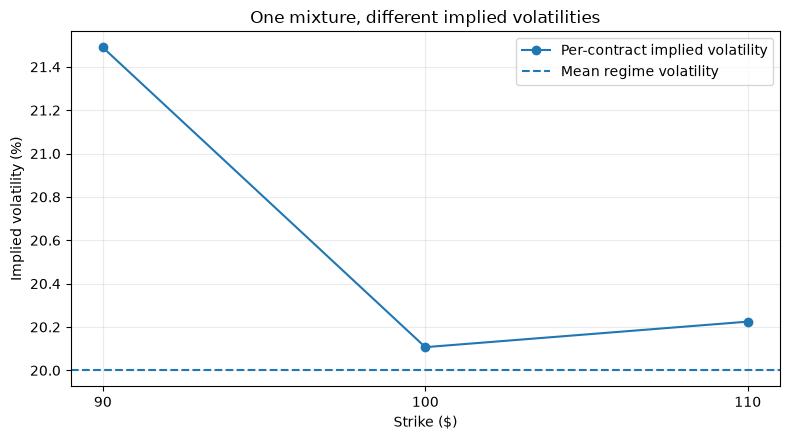

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(mixture_price_df["Strike"], mixture_price_df["Implied Volatility (%)"],
        marker="o", label="Per-contract implied volatility")
ax.axhline(100 * sigma_benchmark, linestyle="--", label="Mean regime volatility")
ax.set(xlabel="Strike ($)", ylabel="Implied volatility (%)",
       title="One mixture, different implied volatilities")
ax.set_xticks(strikes)
ax.legend()
ax.grid(alpha=0.25)
save_figure(fig, "02_mixture_implied_volatility.png")

The implied volatilities are approximately 21.4894%, 20.1070%, and 20.2247% at strikes 90, 100, and 110, respectively. Their differences establish that no single constant volatility reproduces all three benchmark prices exactly. Separate inversion of each price is a description of this incompatibility, not a predictive test. The three-strike sample is also insufficient to characterize a complete implied-volatility smile.

### 2.1 Curvature and the mixture-price difference

The dependence of option value on volatility provides a mathematical explanation for the difference between the average of regime prices and the price at average volatility. Vega and Volga measure the first and second derivatives of the call price:

$$
V=\frac{\partial C}{\partial\sigma}=S_0\phi(d_1)\sqrt{T},
\qquad
W=\frac{\partial^2 C}{\partial\sigma^2}=V\frac{d_1d_2}{\sigma},
$$

where $\phi$ is the standard normal density and

$$
d_1=\frac{\log(S_0/K)+(r+\sigma^2/2)T}{\sigma\sqrt{T}},
\qquad d_2=d_1-\sigma\sqrt{T}.
$$

Vega is expressed per unit change in decimal volatility; a one-percentage-point change corresponds to a first-order price change of $0.01V$. Volga describes how this sensitivity changes with volatility.

For the symmetric 10%/30% mixture, a second-order Taylor expansion about 20% gives

$$
C_{\mathrm{mix}}-C_{\mathrm{BS}}(0.20)
\approx \tfrac12 W(0.20)(0.10)^2=0.005W(0.20).
$$

The first-order Vega terms cancel when the two regimes are averaged. The remaining second-order term is an approximation to the exact mixture-price difference. The following table compares the approximation with the exact result and verifies analytical Vega against a central finite difference with step $h=0.0001$.

In [6]:
def bs_vega(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    return S * norm.pdf(d1) * np.sqrt(T)


def bs_volga(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return bs_vega(S, K, T, r, sigma) * d1 * d2 / sigma


curvature_rows = []
h = 0.0001
regime_variance = sum(
    weight * (sigma - sigma_benchmark)**2
    for weight, sigma in worlds["mixture"]
)
for strike in strikes:
    vega = bs_vega(S0, strike, maturity, rate, sigma_benchmark)
    numeric_vega = (
        bs_call(S0, strike, maturity, rate, sigma_benchmark + h)
        - bs_call(S0, strike, maturity, rate, sigma_benchmark - h)
    ) / (2 * h)
    volga = bs_volga(S0, strike, maturity, rate, sigma_benchmark)
    exact_gap = exact_price(strike, worlds["mixture"]) - benchmark_prices[strike]
    predicted_gap = 0.5 * volga * regime_variance
    assert np.isclose(vega, numeric_vega, rtol=1e-6, atol=1e-7)
    curvature_rows.append({
        "Strike": strike,
        "Analytical Vega": vega,
        "Finite-difference Vega": numeric_vega,
        "Volga": volga,
        "Exact Mixture minus BS ($)": exact_gap,
        "Volga Prediction ($)": predicted_gap,
        "Absolute Approximation Error ($)": abs(predicted_gap - exact_gap),
    })
curvature_df = pd.DataFrame(curvature_rows)
display(curvature_df.round(6))

,Strike,Analytical Vega,Finite-difference Vega,Volga,Exact Mixture minus BS ($),Volga Prediction ($),Absolute Approximation Error ($)
0,90,28.344426,28.344425,73.446359,0.429817,0.367232,0.062585
1,100,38.138782,38.138781,5.720817,0.040809,0.028604,0.012205
2,110,39.277292,39.277292,13.055850,0.088299,0.065279,0.023020


The Volga correction captures part of the mixture-price difference but understates it at all three tested strikes. Its largest contribution occurs at strike 90, which also has the largest exact difference from the price at mean volatility. The residuals in this table are Taylor-approximation errors, distinct from the model-pricing errors studied next.

### 2.2 Calibration and pricing at excluded strikes

A single volatility is calibrated to the exact 100-strike price in each benchmark model. That fitted volatility is then held fixed when pricing the 80-, 90-, 110-, and 120-strike contracts. The calibration contract is excluded from the validation set.

Calibration recovers 20% volatility in the constant-volatility control and approximately 20.107% in the mixture. The exact prices at excluded strikes establish the true discrepancies that the Monte Carlo validation procedure will attempt to detect. Using an exact calibration price isolates simulation uncertainty from calibration uncertainty; this experiment does not estimate parameters from noisy market observations.

In [7]:
setup = {}
for world, regimes in worlds.items():
    calibration_price = exact_price(calibration_strike, regimes)

    # Fit once to an exact K=100 synthetic quote, not to noisy MC estimates.
    fitted_sigma = brentq(
        lambda sigma: (
            bs_call(S0, calibration_strike, maturity, rate, sigma) - calibration_price
        ),
        0.05,
        0.50,
    )

    model = np.array([
        bs_call(S0, K, maturity, rate, fitted_sigma)
        for K in test_strikes
    ])
    truth = np.array([exact_price(K, regimes) for K in test_strikes])

    setup[world] = {
        "sigma": fitted_sigma,
        "model": model,
        "truth": truth,
    }

    print(f"{world}: fitted volatility = {fitted_sigma:.8%}")

assert np.isclose(setup["control"]["sigma"], 0.20, atol=1e-10, rtol=0)
assert np.allclose(
    setup["control"]["model"], setup["control"]["truth"],
    atol=1e-10, rtol=0
)


heldout_rows = []
for world in worlds:
    for i, strike in enumerate(test_strikes):
        truth = setup[world]["truth"][i]
        model = setup[world]["model"][i]
        test_set = next(name for name, indices in test_sets.items() if i in indices)
        heldout_rows.append({
            "World": world,
            "Test set": test_set,
            "Strike": strike,
            "Fitted Volatility (%)": 100 * setup[world]["sigma"],
            "Exact Benchmark": truth,
            "Fitted BS Price": model,
            "Signed Error ($)": model - truth,
            "Absolute Error ($)": abs(model - truth),
            "Relative Error (%)": 100 * (model - truth) / truth,
        })
heldout_df = pd.DataFrame(heldout_rows)
display(heldout_df[heldout_df["World"] == "mixture"].round(5).reset_index(drop=True))

control: fitted volatility = 20.00000000%
mixture: fitted volatility = 20.10699380%


,World,Test set,Strike,Fitted Volatility (%),Exact Benchmark,Fitted BS Price,Signed Error ($),Absolute Error ($),Relative Error (%)
0,mixture,wide,80.0,20.10699,24.51025,23.92190,-0.58834,0.58834,-2.40039
1,mixture,near,90.0,20.10699,16.49025,16.09080,-0.39945,0.39945,-2.42233
2,mixture,near,110.0,20.10699,5.74709,5.70082,-0.04627,0.04627,-0.80506
3,mixture,wide,120.0,20.10699,3.48301,3.03540,-0.44761,0.44761,-12.85124


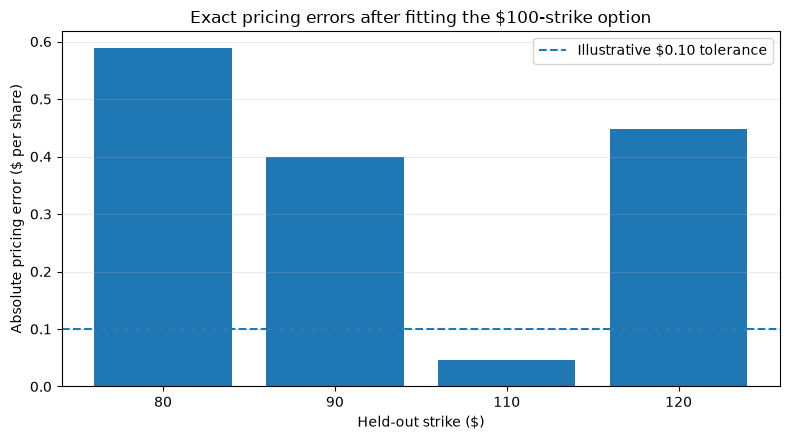

In [8]:
heldout_mixture = heldout_df[heldout_df["World"] == "mixture"].sort_values("Strike")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(heldout_mixture["Strike"].astype(int).astype(str),
       heldout_mixture["Absolute Error ($)"])
ax.axhline(primary_tolerance, linestyle="--", label="Illustrative $0.10 tolerance")
ax.set(xlabel="Held-out strike ($)", ylabel="Absolute pricing error ($ per share)",
       title="Exact pricing errors after fitting the $100-strike option")
ax.legend()
ax.grid(axis="y", alpha=0.25)
save_figure(fig, "03_calibrated_pricing_errors.png")

## 3. Reliability of Monte Carlo validation

Exact benchmark prices establish whether the calibrated model has a pricing discrepancy. A separate question is whether a simulation-based validation procedure can reliably detect that discrepancy. In this experiment, the flagging decision uses Monte Carlo estimates and their standard errors rather than the exact benchmark prices. The exact values remain available for determining whether a discrepancy actually exists.

A trial uses $N$ simulated terminal stock prices to estimate option values and standard errors, then produces one flag/no-flag decision for each two-contract test set. Repeating the trial with fresh random draws estimates the probability of detection or false alarm. Increasing $N$ changes the precision of the validation evidence, not the calibrated model's true pricing error.

### 3.1 Experimental design and decision rule

| Setting | Specification |
|---|---|
| Control benchmark | Constant 20% volatility; exact 100-strike calibration |
| Alternative benchmark | Equal-probability 10%/30% mixture; exact 100-strike calibration |
| Near-strike test set | Strikes 90 and 110 |
| Wide-strike test set | Strikes 80 and 120 |
| Terminal-price samples per trial | 1,000; 10,000; 100,000 in total across regimes |
| Independent trials per benchmark and budget | 500 |
| Random seed | 20261103 |
| Primary pricing tolerance | 0.10 dollars per share |
| Secondary tolerances | 0 and 0.05 dollars per share |
| Intended false-alarm ceiling | 5% within each two-contract procedure |
| Detection target | At least 90% under the specified material-error alternative |

The 0.10-dollar tolerance is an illustrative research choice, not an industry standard. For fitted price $B_j$, Monte Carlo benchmark $\widehat C_j$, estimated standard error $SE_j$, and tolerance $\tau$, the procedure flags a discrepancy if at least one tested contract satisfies

$$
|B_j-\widehat C_j|>\tau+z_*SE_j,
\qquad
z_*=\Phi^{-1}\!\left(1-\frac{0.05}{2\cdot2}\right)\approx2.2414.
$$

The observed pricing gap must therefore exceed **the sum of the tolerance and the allowance for simulation uncertainty**. The Bonferroni adjustment accounts for testing two contracts and does not require their estimates to be independent [1]. The underlying price intervals are normal approximations rather than exact finite-sample guarantees.

The reported control and mixture results address different questions. In the control, $\tau=0$ and any flag is a false alarm because the model is exactly correct. In the primary mixture comparison, $\tau=0.10$ and a flag provides evidence that an error exceeds that tolerance. The control does not establish false-alarm behavior for all nonzero errors just below the materiality threshold. In either case, failure to flag is inconclusive; it does not establish that pricing errors lie within tolerance.

In [9]:
def mc_estimates(N, regimes, rng):
    """MC prices and SEs at all four strikes.

    Independent half-samples in the two regimes reproduce the stratified
    estimator in pricing_validation.ipynb. Terminal prices are shared
    across strikes within a trial.
    """
    if not isinstance(N, (int, np.integer)) or N < 4 or N % 2:
        raise ValueError("N must be an even integer >= 4.")

    estimate = np.zeros(len(test_strikes))
    estimator_var = np.zeros(len(test_strikes))

    for weight, sigma in regimes:
        n = int(N * weight)  # Exact for the fixed weights 1 and 1/2.
        Z = rng.standard_normal(n)
        ST = S0 * np.exp(
            (rate - 0.5 * sigma**2) * maturity
            + sigma * np.sqrt(maturity) * Z
        )

        payoffs = np.exp(-rate * maturity) * np.maximum(
            ST[:, None] - test_strikes, 0
        )

        estimate += weight * payoffs.mean(axis=0)
        estimator_var += (
            weight**2 * payoffs.var(axis=0, ddof=1) / n
        )

    return estimate, np.sqrt(estimator_var)


# Replication targets from pricing_validation.ipynb at K=90 and K=110.
check_prices, check_se = mc_estimates(
    100_000, worlds["mixture"], np.random.default_rng(2026)
)
assert np.allclose(
    check_prices[[1, 2]], [16.4560, 5.7031],
    atol=0.0001, rtol=0
)
print("Simulation check agrees with the companion notebook's mixture estimates.")

replication_df = pd.DataFrame({
    "Strike": test_strikes[[1, 2]],
    "Reproduced MC Price": check_prices[[1, 2]],
    "MC SE": check_se[[1, 2]],
    "Companion MC Price": [16.4560, 5.7031],
})
display(replication_df.round(4))

Simulation check agrees with the companion notebook's mixture estimates.


,Strike,Reproduced MC Price,MC SE,Companion MC Price
0,90.0,16.4560,0.0597,16.4560
1,110.0,5.7031,0.0436,5.7031


### 3.2 Replication and repeated-trial estimation

The simulation uses the stratified estimator established in `pricing_validation.ipynb`: half the samples are generated in each volatility regime, with independent draws between regimes. The mixture price estimate and its standard error satisfy

$$
\widehat C_{\mathrm{mix}}=\tfrac12\widehat C_{\mathrm{low}}
+\tfrac12\widehat C_{\mathrm{high}},
\qquad
SE_{\mathrm{mix}}^2=\tfrac14SE_{\mathrm{low}}^2+\tfrac14SE_{\mathrm{high}}^2.
$$

Terminal prices are shared across strikes within each trial, preserving dependence between the resulting option-price estimates. Fresh draws are used between trials. The replication check above reproduces the companion notebook's reported mixture estimates at strikes 90 and 110.

For each configuration, the fraction of flagged trials estimates the flag probability. Individual 95% Wilson intervals quantify uncertainty in that probability [2, 4]. These intervals describe variation across repeated validation trials, whereas the Monte Carlo price intervals describe uncertainty within a single trial. The probability intervals are not simultaneous across all study configurations.

In [10]:
def run_study(repeats=REPETITIONS, seed=SEED):
    """Repeat complete validation trials and summarize flag probabilities."""
    if not isinstance(repeats, (int, np.integer)) or repeats < 1:
        raise ValueError("repeats must be a positive integer.")

    # A single seeded generator supplies fresh draws across repetitions.
    rng = np.random.default_rng(seed)
    records = []

    for world, regimes in worlds.items():
        model = setup[world]["model"]
        truth = setup[world]["truth"]

        for N in budgets:
            flags = {
                name: np.zeros((repeats, len(tolerances)), dtype=bool)
                for name in test_sets
            }

            for rep in range(repeats):
                estimate, se = mc_estimates(N, regimes, rng)

                abs_gap = np.abs(model - estimate)
                margin = critical * se

                for name, idx in test_sets.items():
                    # Flag only when the entire error CI lies beyond
                    # the tolerance for at least one tested contract.
                    flags[name][rep] = np.any(
                        abs_gap[idx, None]
                        > tolerances[None, :] + margin[idx, None],
                        axis=0,
                    )

            print(f"Completed {world}: N={N:,}; {repeats} trials")

            for name, idx in test_sets.items():
                true_max_error = np.max(
                    np.abs(model[idx] - truth[idx])
                )

                for j, tolerance in enumerate(tolerances):
                    k = int(flags[name][:, j].sum())

                    # Uncertainty across independent validation trials,
                    # not the uncertainty of an individual option price.
                    ci = binomtest(k, repeats).proportion_ci(
                        confidence_level=0.95, method="wilson"
                    )

                    records.append({
                        "World": world,
                        "Paths": N,
                        "Test set": name,
                        "Tolerance ($)": tolerance,
                        "True max error ($)": true_max_error,
                        "Flags": k,
                        "Trials": repeats,
                        "Flag rate": k / repeats,
                        "CI low": ci.low,
                        "CI high": ci.high,
                    })

    return pd.DataFrame(records)


study_df = run_study()

Completed control: N=1,000; 500 trials
Completed control: N=10,000; 500 trials
Completed control: N=100,000; 500 trials
Completed mixture: N=1,000; 500 trials
Completed mixture: N=10,000; 500 trials
Completed mixture: N=100,000; 500 trials


### 3.3 False-alarm and detection results

The control summary reports false alarms under an exactly correct pricing model. The mixture summary reports detection of a true pricing discrepancy above the 0.10-dollar tolerance; an unflagged trial in this setting is a missed detection.

The evidence criterion requires an upper 95% confidence bound no greater than 5% for the control false-alarm rate and a lower bound of at least 90% for mixture detection. An interval overlapping a target is insufficient to confirm the criterion, not proof that the procedure fails it. The assessment applies to the specified benchmark cases and is not a general certification of the test.

In [11]:
def readable_rates(table):
    result = table.copy()
    for col in ["Flag rate", "CI low", "CI high"]:
        result[col] *= 100
    return result.rename(columns={
        "Flag rate": "Flag rate (%)",
        "CI low": "95% CI low (%)",
        "CI high": "95% CI high (%)",
    })


# Control: any flag is a false alarm, since the model is correct.
control_results = study_df[
    (study_df["World"] == "control")
    & (study_df["Tolerance ($)"] == 0.0)
]
print("CONTROL: false-alarm rates")
display(readable_rates(control_results).round(3).reset_index(drop=True))

# Primary mixture result: evidence of an error greater than $0.10/share.
detection_results = study_df[
    (study_df["World"] == "mixture")
    & np.isclose(study_df["Tolerance ($)"], primary_tolerance)
]
print("MIXTURE: material-error detection rates")
display(readable_rates(detection_results).round(3).reset_index(drop=True))

# Evidence categories, rather than automatic pass/fail from one estimate.
assessment = control_results[
    ["Paths", "Test set", "CI low", "CI high"]
].merge(
    detection_results[["Paths", "Test set", "CI low", "CI high"]],
    on=["Paths", "Test set"],
    suffixes=("_false_alarm", "_detection"),
)

assessment["Control evidence"] = np.select(
    [
        assessment["CI high_false_alarm"] <= 0.05,
        assessment["CI low_false_alarm"] > 0.05,
    ],
    [
        "Upper CI supports false-alarm rate <= 5%",
        "Lower CI indicates false-alarm rate > 5%",
    ],
    default="Inconclusive relative to 5% threshold",
)
assessment["Detection target supported"] = (
    assessment["CI low_detection"] >= 0.90
)

display(assessment[
    ["Paths", "Test set", "Control evidence", "Detection target supported"]
])

CONTROL: false-alarm rates


,World,Paths,Test set,Tolerance ($),True max error ($),Flags,Trials,Flag rate (%),95% CI low (%),95% CI high (%)
0,control,1000,near,0.0,0.0,23,500,4.6,3.085,6.808
1,control,1000,wide,0.0,0.0,23,500,4.6,3.085,6.808
2,control,10000,near,0.0,0.0,17,500,3.4,2.133,5.377
3,control,10000,wide,0.0,0.0,20,500,4.0,2.604,6.097
4,control,100000,near,0.0,0.0,12,500,2.4,1.378,4.148
5,control,100000,wide,0.0,0.0,15,500,3.0,1.826,4.890


MIXTURE: material-error detection rates


,World,Paths,Test set,Tolerance ($),True max error ($),Flags,Trials,Flag rate (%),95% CI low (%),95% CI high (%)
0,mixture,1000,near,0.1,0.399,28,500,5.6,3.903,7.974
1,mixture,1000,wide,0.1,0.588,49,500,9.8,7.492,12.721
2,mixture,10000,near,0.1,0.399,120,500,24.0,20.464,27.933
3,mixture,10000,wide,0.1,0.588,400,500,80.0,76.271,83.271
4,mixture,100000,near,0.1,0.399,500,500,100.0,99.238,100.000
5,mixture,100000,wide,0.1,0.588,500,500,100.0,99.238,100.000


,Paths,Test set,Control evidence,Detection target supported
0,1000,near,Inconclusive relative to 5% threshold,False
1,1000,wide,Inconclusive relative to 5% threshold,False
2,10000,near,Inconclusive relative to 5% threshold,False
3,10000,wide,Inconclusive relative to 5% threshold,False
4,100000,near,Upper CI supports false-alarm rate <= 5%,True
5,100000,wide,Upper CI supports false-alarm rate <= 5%,True


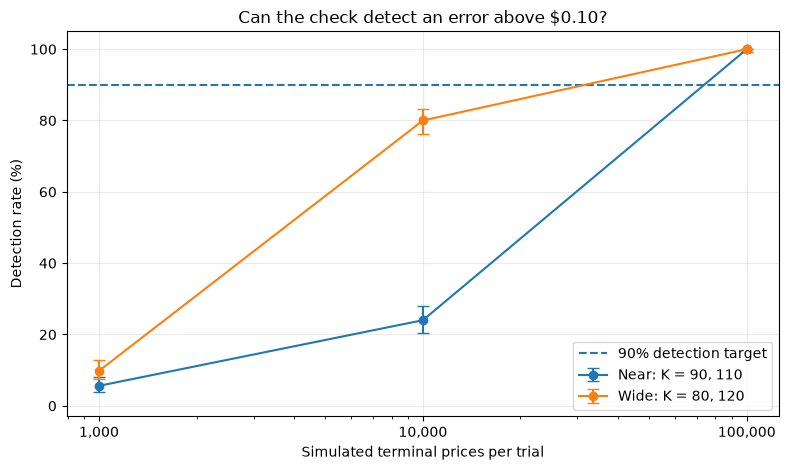

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for name in test_sets:
    subset = detection_results[detection_results["Test set"] == name].sort_values("Paths")
    y = 100 * subset["Flag rate"].to_numpy()
    error_bars = np.vstack([
        y - 100 * subset["CI low"].to_numpy(),
        100 * subset["CI high"].to_numpy() - y,
    ])
    labels = {"near": "Near: K = 90, 110", "wide": "Wide: K = 80, 120"}
    ax.errorbar(subset["Paths"], y, yerr=np.maximum(error_bars, 0),
                marker="o", capsize=4, label=labels[name])
ax.axhline(100 * detection_target, linestyle="--", label="90% detection target")
ax.set_xscale("log")
ax.set_xticks(budgets, [f"{n:,}" for n in budgets])
ax.set(xlabel="Simulated terminal prices per trial", ylabel="Detection rate (%)",
       title="Can the check detect an error above $0.10?", ylim=(-3, 105))
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
save_figure(fig, "04_material_error_detection.png")

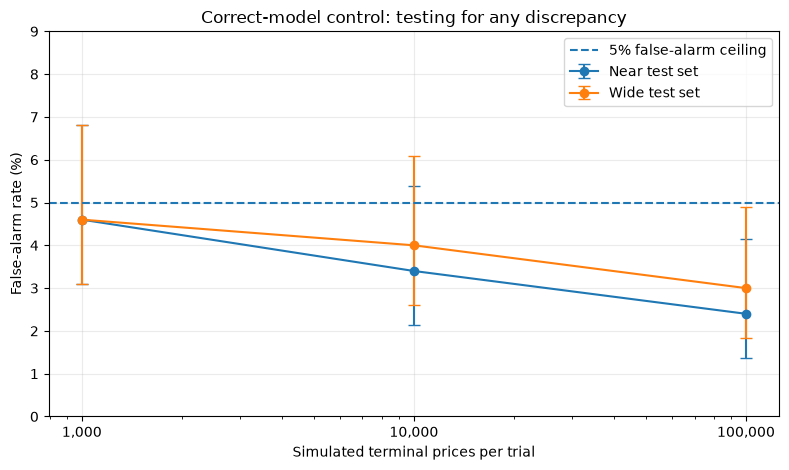

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for name in test_sets:
    subset = control_results[control_results["Test set"] == name].sort_values("Paths")
    y = 100 * subset["Flag rate"].to_numpy()
    error_bars = np.vstack([
        y - 100 * subset["CI low"].to_numpy(),
        100 * subset["CI high"].to_numpy() - y,
    ])
    ax.errorbar(subset["Paths"], y, yerr=np.maximum(error_bars, 0),
                marker="o", capsize=4, label=name.capitalize() + " test set")
ax.axhline(100 * alpha, linestyle="--", label="5% false-alarm ceiling")
ax.set_xscale("log")
ax.set_xticks(budgets, [f"{n:,}" for n in budgets])
ax.set(xlabel="Simulated terminal prices per trial", ylabel="False-alarm rate (%)",
       title="Correct-model control: testing for any discrepancy", ylim=(0, 9))
ax.legend()
ax.grid(alpha=0.25)
save_figure(fig, "05_control_false_alarms.png")

## 4. Discussion and Conclusions

The pricing and validation experiments address different aspects of model reliability. Exact mixture prices identify discrepancies that remain after calibration, while repeated Monte Carlo trials evaluate the ability of a statistical validation procedure to detect them.

Our results demonstrate that calibrating Black–Scholes to a single option does not guarantee accurate pricing across other strikes when the model's volatility assumptions are violated. Under the two-regime benchmark, the largest pricing errors after calibration were \$0.399 per share for the near-strike set and $0.588 for the wide-strike set.

The Monte Carlo validation experiment further demonstrates that the ability to detect these discrepancies depends on simulation precision. With 10,000 simulated paths per trial, detection rates were 24% and 80% for the near- and wide-strike sets, respectively. With 100,000 paths, both achieved an observed detection rate of 100% across 500 trials. The underlying pricing errors remained unchanged as the simulation budget increased.

At 100,000 paths, both test configurations satisfied our stated statistical evidence criteria: the confidence bounds supported a false-alarm probability no greater than 5% and a detection probability of at least 90%. The error bars in the preceding figures represent 95% Wilson confidence intervals estimated from the repeated trials.

These findings highlight the distinction between numerical implementation correctness, model adequacy, and statistical validation reliability. They apply to our specified synthetic benchmarks and validation procedure rather than establishing Black–Scholes' accuracy in actual financial markets.

### 4.1 Limitations

All benchmark and calibration prices are synthetic. The regime probabilities are specified risk-neutral weights, not estimates from historical returns, and the chosen volatility remains fixed throughout each path. The study does not evaluate dynamic regime switching, real-market pricing, noisy calibration, hedging, or trading performance.

The reliability results are specific to the estimator, contract sets, simulation budgets, and tolerances examined. The near and wide sets differ in both true pricing errors and payoff variability, so their comparison does not isolate strike distance as a causal factor. An observed detection rate of 100% across 500 trials does not establish a population detection probability of exactly 100%.

The control evaluates one zero-error scenario at zero tolerance, not every case within the 0.10-dollar materiality boundary. Reported probability intervals are individual rather than simultaneous across the full set of configurations. The evidence criteria therefore support conclusions about these cases, not a universal simulation budget or a guarantee for other validation tasks. Analyses revised after observing these results would be exploratory.

## 5. Reproducibility

The analysis imports the common pricing function from `bs_model.py` and records the financial inputs, test sets, simulation budgets, tolerances, random seed, and package versions. Full-precision tables, run settings, and the findings summary are exported to `results/volatility_validation/`; the five figures are exported to `figures/volatility_validation/`. Rounding affects displayed tables only. The source pricing module and companion notebook are not modified.

In [15]:
tables_to_save = {
    "volatility_sensitivity.csv": sensitivity_df,
    "mixture_prices_and_iv.csv": mixture_price_df,
    "vega_volga_support.csv": curvature_df,
    "calibrated_heldout_prices.csv": heldout_df,
    "companion_replication_check.csv": replication_df,
    "validation_reliability_results.csv": study_df,
    "control_false_alarms.csv": control_results,
    "mixture_detection.csv": detection_results,
    "validation_assessment.csv": assessment,
}
for name, table in tables_to_save.items():
    table.to_csv(results_dir / name, index=False)

run_settings = {
    "S0": S0, "maturity": maturity, "risk_free_rate": rate,
    "benchmark_volatility": sigma_benchmark,
    "calibration_strike": calibration_strike,
    "test_strikes": test_strikes.tolist(),
    "test_sets": {name: test_strikes[indices].tolist() for name, indices in test_sets.items()},
    "worlds": worlds, "budgets": budgets, "tolerances": tolerances.tolist(),
    "primary_tolerance": primary_tolerance, "alpha": alpha,
    "detection_target": detection_target, "repetitions": REPETITIONS,
    "seed": SEED, "critical_value": float(critical),
    "environment": versions,
    "source_notebooks": ["volatility_analysis.ipynb", "validation_reliability.ipynb"],
}
(results_dir / "run_settings.json").write_text(json.dumps(run_settings, indent=2))
(results_dir / "findings.txt").write_text(finding_text + "\n")
print(f"Saved {len(tables_to_save)} full-precision tables, settings, and findings to {results_dir}/")
print(f"Saved {len(saved_figures)} figures to {figures_dir}/")

Saved 9 full-precision tables, settings, and findings to results/volatility_validation/
Saved 5 figures to figures/volatility_validation/


## References

**Companion analysis.** `pricing_validation.ipynb` contains the independent Monte Carlo verification of analytical Black-Scholes prices and the two-regime benchmark. Its reported mixture estimates provide the replication targets used in Section 3. The numerical inputs and results reported here are generated by the synthetic experiments in this notebook.

**Method references.** The following sources document the statistical procedures and numerical routines; they are not sources of empirical option prices.

1. NIST/SEMATECH. [Bonferroni's method](https://www.itl.nist.gov/div898/handbook/prc/section4/prc473.htm).
2. NIST/SEMATECH. [Confidence intervals for proportions](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm).
